In [5]:
from NN import LNN_Regression
import numpy as np

'Für die Parameter m=2 und k=0.5 Trainieren wir das LNN um folgende Dynamik zu lernen'
'qdd(t) + 1/4 q(t) = 0 -> q(t) = 2qd(0) sin(t/2)+ q(0)cos(t/2)'
'Wir testen am Ende auf dem Startpunkt q(0)= 0 und qd(0) = 1'

np.random.seed(42)
h = 20
model = LNN_Regression(layers=h, activation_method='softplus')
model.read_data("spring_data_no_control.csv")

_, _, _, H = model.L_derivatives(model.X)
print(f"H_min={H.min():.4f}  H_mean={H.mean():.4f}  neg={np.mean(H<=0):.4f}")
print(f"Loss: {model.loss():.4e}")
print("K =", model.K, "M =", model.M, "N =", model.N)
print("Loss:", model.loss())
gW1, gb1, gWN = model.gradient_descent()
print(f"[Start] ||g_W1||={np.linalg.norm(gW1):.4e}  "
      f"||g_b1||={np.linalg.norm(gb1):.4e}  "
      f"||g_WN||={np.linalg.norm(gWN):.4e}  "
      f"W1/WN={np.linalg.norm(gW1)/max(np.linalg.norm(gWN), 1e-30):.4e}")

Episodes = 100
for epoch in range(Episodes):
    model.train_step(1e-4)
    if epoch % int(Episodes/10) == 0:
        print(f"Epoch {epoch:4d}  Loss = {model.loss():.6f}")

# nach dem Training → NEU berechnen
_, _, _, H_after = model.L_derivatives(model.X)
gW1, gb1, gWN = model.gradient_descent()
print(f"[Ende]  ||g_W1||={np.linalg.norm(gW1):.4e}  "
      f"||g_b1||={np.linalg.norm(gb1):.4e}  "
      f"||g_WN||={np.linalg.norm(gWN):.4e}  "
      f"W1/WN={np.linalg.norm(gW1)/max(np.linalg.norm(gWN), 1e-30):.4e}")
print(f"Loss: {model.loss():.6e}")
print(f"Nachher: Loss = {model.loss():.6f}  H_min={H_after.min():.4f}  H_mean={H_after.mean():.4f}")

H_min=0.0034  H_mean=0.0034  neg=0.0000
Loss: 9.3548e+01
K = 25000 M = 50 N = 500
Loss: 93.54827471882957
[Start] ||g_W1||=1.4203e+03  ||g_b1||=4.5487e+01  ||g_WN||=1.5308e+03  W1/WN=9.2782e-01
Epoch    0  Loss = 1.558459
Epoch   10  Loss = 0.477768
Epoch   20  Loss = 0.452120
Epoch   30  Loss = 0.435641
Epoch   40  Loss = 0.420704
Epoch   50  Loss = 0.407049
Epoch   60  Loss = 0.394514
Epoch   70  Loss = 0.382962
Epoch   80  Loss = 0.372279
Epoch   90  Loss = 0.362367
[Ende]  ||g_W1||=2.2605e+00  ||g_b1||=7.7885e-04  ||g_WN||=1.9596e+00  W1/WN=1.1535e+00
Loss: 3.540378e-01
Nachher: Loss = 0.354038  H_min=0.0085  H_mean=0.0087


In [6]:
Episodes = 20000
for epoch in range(Episodes):
    model.train_step(1e-4)
    if epoch % int(Episodes/10) == 0:
        print(f"Epoch {epoch:4d}  Loss = {model.loss():.6f}")

# nach dem Training → NEU berechnen
_, _, _, H_after = model.L_derivatives(model.X)
gW1, gb1, gWN = model.gradient_descent()
print(f"[Ende]  ||g_W1||={np.linalg.norm(gW1):.4e}  "
      f"||g_b1||={np.linalg.norm(gb1):.4e}  "
      f"||g_WN||={np.linalg.norm(gWN):.4e}  "
      f"W1/WN={np.linalg.norm(gW1)/max(np.linalg.norm(gWN), 1e-30):.4e}")
print(f"Loss: {model.loss():.6e}")
print(f"Nachher: Loss = {model.loss():.6f}  H_min={H_after.min():.4f}  H_mean={H_after.mean():.4f}")

Epoch    0  Loss = 0.353144
Epoch 2000  Loss = 0.092450
Epoch 4000  Loss = 0.001742
Epoch 6000  Loss = 0.000010
Epoch 8000  Loss = 0.000010
Epoch 10000  Loss = 0.000010
Epoch 12000  Loss = 0.000010
Epoch 14000  Loss = 0.000010
Epoch 16000  Loss = 0.000010
Epoch 18000  Loss = 0.000010
[Ende]  ||g_W1||=7.6595e-05  ||g_b1||=4.2865e-06  ||g_WN||=2.1154e-05  W1/WN=3.6209e+00
Loss: 9.631493e-06
Nachher: Loss = 0.000010  H_min=0.0075  H_mean=0.0077


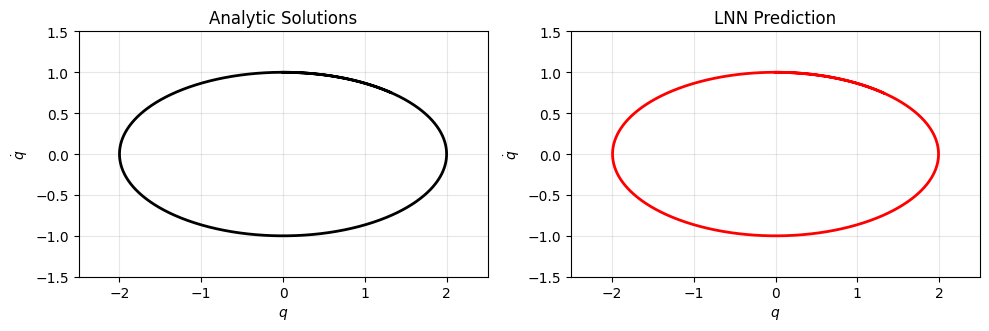

q_l   range: -1.9931391645277288 1.9929724116267278
qd_l  range: -0.9999735365901048 1.0


In [3]:
import matplotlib.pyplot as plt
import numpy as np

omega = 0.5
def q_analytic(t, q0, qdot0):
    return q0*np.cos(omega*t) + (qdot0/omega)*np.sin(omega*t)

def qddot_learned(q, qdot, u=0):
    dLdq, _, C, H = model.forward(q, qdot)
    return (dLdq[0] - C[0]*qdot + u) / H[0]

def rk4_step(q, qdot, u, h):
    k1_q, k1_qd = qdot, qddot_learned(q, qdot, u)
    k2_q, k2_qd = qdot+h/2*k1_qd, qddot_learned(q+h/2*k1_q, qdot+h/2*k1_qd, u)
    k3_q, k3_qd = qdot+h/2*k2_qd, qddot_learned(q+h/2*k2_q, qdot+h/2*k2_qd, u)
    k4_q, k4_qd = qdot+h*k3_qd,   qddot_learned(q+h*k3_q,   qdot+h*k3_qd,   u)
    return q+h/6*(k1_q+2*k2_q+2*k3_q+k4_q), qdot+h/6*(k1_qd+2*k2_qd+2*k3_qd+k4_qd)

h = 0.01
T_end = 14.0
t_grid = np.arange(0, T_end + h, h)

q0, qdot0 = 0.0, 1.0

q_l = np.zeros(len(t_grid))
qd_l = np.zeros(len(t_grid))
q_l[0], qd_l[0] = q0, qdot0
for i in range(len(t_grid)-1):
    q_l[i+1], qd_l[i+1] = rk4_step(q_l[i], qd_l[i], 0.0, h)

q_true  = q_analytic(t_grid, q0, qdot0)
qd_true = -q0*omega*np.sin(omega*t_grid) + qdot0*np.cos(omega*t_grid)

fig, ax = plt.subplots(1, 2, figsize=(10, 6))

# Analytisch
ax[0].plot(q_true, qd_true, 'k-', linewidth=2, label='Analytisch')
ax[0].set_xlabel('$q$')
ax[0].set_ylabel('$\\dot q$')
ax[0].set_title('Analytic Solutions')
ax[0].grid(alpha=0.3)
ax[0].set_aspect('equal')

# LNN
ax[1].plot(q_l, qd_l, 'r-', linewidth=2, label='LNN')
ax[1].set_xlabel('$q$')
ax[1].set_ylabel('$\\dot q$')
ax[1].set_title('LNN Prediction')
ax[1].grid(alpha=0.3)
ax[1].set_aspect('equal')

# Gemeinsame Grenzen für beide
xlim = (-2.5, 2.5)
ylim = (-1.5, 1.5)
ax[0].set_xlim(xlim); ax[0].set_ylim(ylim)
ax[1].set_xlim(xlim); ax[1].set_ylim(ylim)

plt.tight_layout()
plt.show()

print("q_l   range:", q_l.min(), q_l.max())
print("qd_l  range:", qd_l.min(), qd_l.max())

c=0.10  seed=0  H0=4.4042e-03  loss_end=1.177e-01  div=False
c=0.10  seed=1  H0=2.4758e-03  loss_end=4.844e-04  div=False
c=0.10  seed=2  H0=5.1486e-03  loss_end=1.857e-04  div=False
c=0.10  seed=3  H0=5.6543e-03  loss_end=9.786e-05  div=False
c=0.10  seed=4  H0=4.0797e-03  loss_end=1.043e-04  div=False
c=0.20  seed=0  H0=3.4561e-02  loss_end=2.785e-04  div=False
c=0.20  seed=1  H0=1.9310e-02  loss_end=3.234e-04  div=False
c=0.20  seed=2  H0=4.0179e-02  loss_end=9.866e-04  div=False
c=0.20  seed=3  H0=4.4457e-02  loss_end=1.154e-03  div=False
c=0.20  seed=4  H0=3.1960e-02  loss_end=4.044e-04  div=False
c=0.30  seed=0  H0=1.1323e-01  loss_end=1.477e-03  div=False
c=0.30  seed=1  H0=6.2792e-02  loss_end=1.351e-03  div=False
c=0.30  seed=2  H0=1.3057e-01  loss_end=3.376e-03  div=False
c=0.30  seed=3  H0=1.4612e-01  loss_end=3.956e-03  div=False
c=0.30  seed=4  H0=1.0442e-01  loss_end=1.568e-03  div=False
c=0.50  seed=0  H0=4.8366e-01  loss_end=1.137e-01  div=False
c=0.50  seed=1  H0=2.647

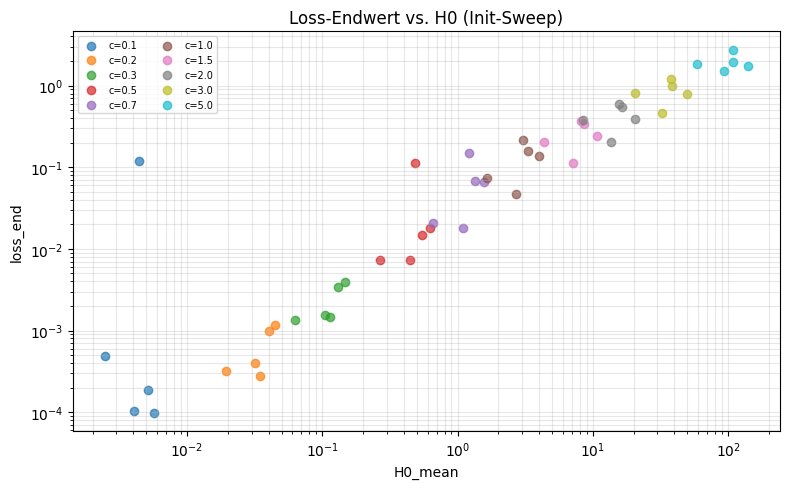

In [ ]:
import numpy as np
from NN import LNN_Regression
import matplotlib.pyplot as plt

def run_one(seed, c, layers=20, N_epochs=8000, lr=5e-4):
    np.random.seed(seed)
    model = LNN_Regression(layers=layers, activation_method='softplus')
    # Skalierung mit c um die Basis 0.1
    model.W1 = c * np.random.randn(layers, 2)
    model.b1 = np.zeros(layers)
    model.WN = c * np.abs(np.random.randn(1, layers))
    model.bN = -5.0 * np.ones(1)
    model.read_data("spring_data_no_control.csv")

    _, _, _, H0 = model.L_derivatives(model.X)
    H0_mean = float(H0.mean())
    loss0 = model.loss()

    divergiert = False
    for epoch in range(N_epochs):
        model.train_step(lr)
        if not np.isfinite(model.loss()):
            divergiert = True
            break

    loss_end = model.loss() if not divergiert else np.nan
    return H0_mean, loss0, loss_end, divergiert


c_values = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0, 5.0]
seeds = [0, 1, 2, 3, 4]

results = []  # (c, H0_mean, loss_end, div)
for c in c_values:
    for s in seeds:
        H0, l0, lE, div = run_one(seed=s, c=c)
        results.append((c, H0, lE, div))
        print(f"c={c:.2f}  seed={s}  H0={H0:.4e}  loss_end={lE:.3e}  div={div}")


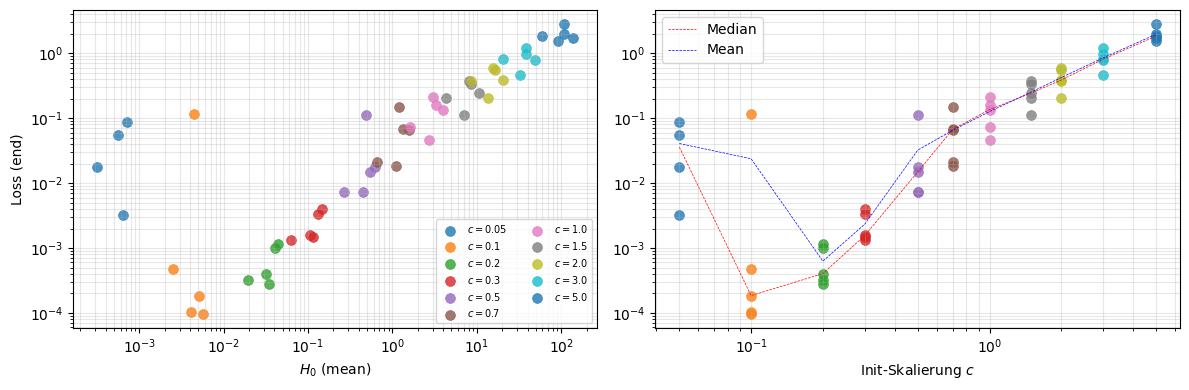

In [27]:
import numpy as np
import matplotlib.pyplot as plt


data = np.loadtxt("init_sweep.csv", delimiter=",", skiprows=1, usecols=(0,1,2))
c_values = data[:, 0]
H0 = data[:, 1]
loss = data[:, 2]

# --- Plot: Loss vs. H0 (log-log), farbcodiert nach c ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for c in np.unique(c_values):
    mask = c_values == c
    ax[0].scatter(H0[mask], loss[mask], s=50, alpha=0.8,
               linewidth=0.5,label=f"$c={c}$")

ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_xlabel(r'$H_0$ (mean)')
ax[0].set_ylabel('Loss (end)')
#ax[0].set_title(r'Loss vs. $H_0$')
ax[0].grid(True, which='both', alpha=0.3)
ax[0].legend(fontsize=7, ncol=2)



for c in np.unique(c_values):
    mask = c_values == c
    ax[1].scatter(c_values[mask], loss[mask], s=50, alpha=0.8, linewidth=0.5)

# Median pro c als Trendlinie
c_unique = np.unique(c_values)
medians = [np.median(loss[c_values == c]) for c in c_unique]
means = [np.mean(loss[c_values == c]) for c in c_unique]
ax[1].plot(c_unique, medians, 'r--', lw=0.5, label='Median')
ax[1].plot(c_unique, means, 'b--', lw=0.5, label='Mean')
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_xlabel('Init-Skalierung $c$')
#ax[1].set_ylabel('Loss (end)')
#ax[1].set_title('Loss vs. Init-Skalierung (5 Seeds pro $c$)')
ax[1].grid(True, which='both', alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.savefig("init_sweep_c.png", dpi=150)
plt.show()

C:\Users\nicol\AppData\Local\Temp\ipykernel_2264\3650062604.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('turbo', n)


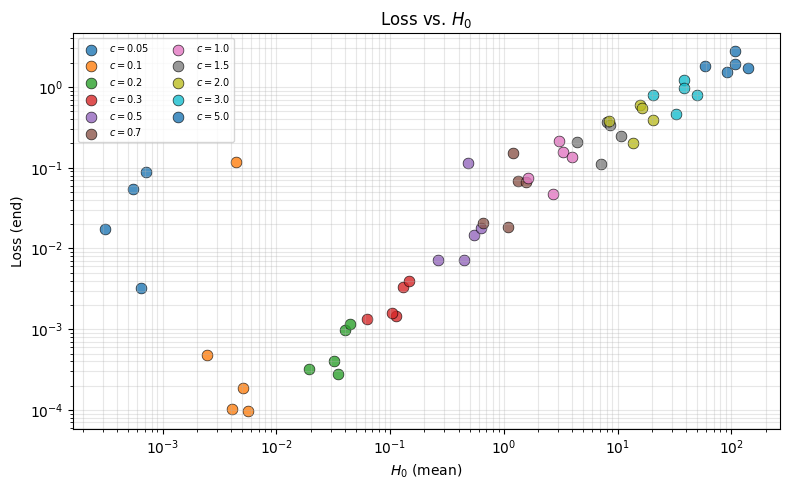

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt("init_sweep.csv", delimiter=",", skiprows=1, usecols=(0, 1, 2))
c_values = data[:, 0]
H0 = data[:, 1]
loss = data[:, 2]

c_unique = np.sort(np.unique(c_values))
n = len(c_unique)
cmap = plt.cm.get_cmap('turbo', n)

fig, ax = plt.subplots(figsize=(8, 5))



for c in np.unique(c_values):
    mask = c_values == c
    ax.scatter(H0[mask], loss[mask], s=60, alpha=0.8,
               edgecolor='black', linewidth=0.5,
               label=f"$c={c}$")

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$H_0$ (mean)')
ax.set_ylabel('Loss (end)')
ax.set_title(r'Loss vs. $H_0$')
ax.grid(True, which='both', alpha=0.3)
ax.legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.savefig("init_sweep_H0.png", dpi=150)
plt.show()